<a href="https://colab.research.google.com/github/hopiies95/data-analytics-portfolio/blob/main/Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.model_selection import train_test_split

# Perform train-test split on clean, aligned datasets
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=12345
)

print("--- Question 22: Train-Test Split Completed ---")
print(f"x_train shape: {x_train.shape}, y_train shape: {y_train.shape}")

--- Question 22: Train-Test Split Completed ---
x_train shape: (7917, 7341), y_train shape: (7917,)


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Train Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=12345)
dt_model.fit(x_train, y_train)

print("--- Question 23: Train Decision Tree Classifier Completed ---")
print("Decision Tree Classifier has been successfully trained.")

--- Question 23: Train Decision Tree Classifier Completed ---
Decision Tree Classifier has been successfully trained.


In [ ]:
import pandas as pd

# Generate predictions on the test set
y_pred = dt_model.predict(x_test)

# Create a comparison DataFrame for the first 20 records
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

print("--- Question 24: First 20 Actual vs. Predicted Statuses ---")
print(comparison_df.head(20))

--- Question 24: First 20 Actual vs. Predicted Statuses ---
           Actual   Predicted
43525  Terminated  Terminated
41390      Active      Active
100       Unknown     Unknown
30538  Terminated  Terminated
5305       Active      Active
42279  Terminated  Terminated
9255       Active      Active
7455       Active      Active
7061       Active      Active
12136  Terminated  Terminated
16179      Active      Active
41036  Terminated  Terminated
28673  Terminated  Terminated
38402  Terminated  Terminated
20313      Active      Active
33258      Active      Active
33962  Terminated  Terminated
47373  Terminated  Terminated
30417  Terminated  Terminated
37958  Terminated  Terminated


--- Question 25: Confusion Matrix ---
[[1975   21   78    0]
 [  36   26   12    0]
 [  86    7 1143    0]
 [   0    0    0   10]]


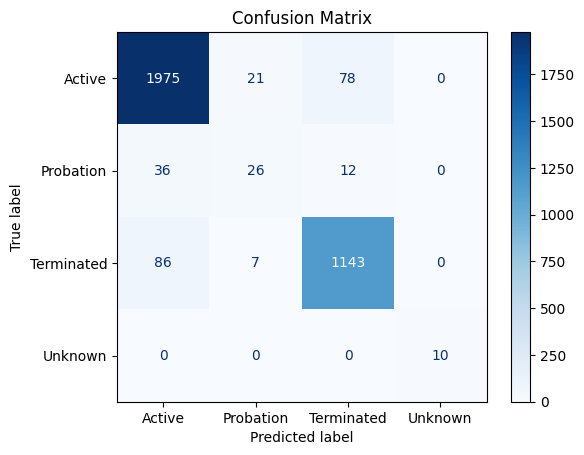

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define the labels in our target class
class_labels = ['Active', 'Probation', 'Terminated', 'Unknown']

# Compute the confusion matrix on the test set
cm = confusion_matrix(y_test, y_pred, labels=class_labels)

print("--- Question 25: Confusion Matrix ---")
print(cm)

# Plot the Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

--- Question 25: Confusion Matrix ---
[[1975   21   78    0]
 [  36   26   12    0]
 [  86    7 1143    0]
 [   0    0    0   10]]


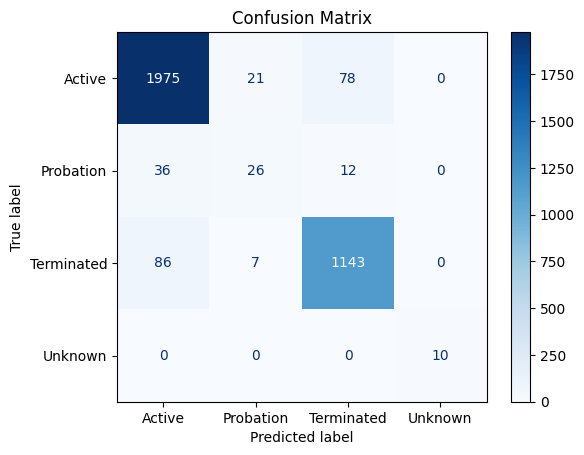

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Define class labels corresponding to our target categories
class_labels = ['Active', 'Probation', 'Terminated', 'Unknown']

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=class_labels)

print("--- Question 25: Confusion Matrix ---")
print(cm)

# Display the confusion matrix visually
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate overall classification accuracy
overall_accuracy = accuracy_score(y_test, y_pred)

# Convert classes to binary targets to evaluate the 'Terminated' class metrics specifically
y_test_binary = (y_test == 'Terminated')
y_pred_binary = (y_pred == 'Terminated')

term_precision = precision_score(y_test_binary, y_pred_binary)
term_recall = recall_score(y_test_binary, y_pred_binary)
term_f1 = f1_score(y_test_binary, y_pred_binary)

print("--- Question 26: Performance Metrics ---")
print(f"Overall Accuracy: {overall_accuracy:.4f}")
print(f"'Terminated' Precision: {term_precision:.4f}")
print(f"'Terminated' Recall: {term_recall:.4f}")
print(f"'Terminated' F1-Score: {term_f1:.4f}")

--- Question 26: Performance Metrics ---
Overall Accuracy: 0.9293
'Terminated' Precision: 0.9270
'Terminated' Recall: 0.9248
'Terminated' F1-Score: 0.9259


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Overall Accuracy
overall_accuracy = accuracy_score(y_test, y_pred)

# 2. Convert target and predictions to binary format for 'Terminated' class evaluation
y_test_binary = (y_test == 'Terminated')
y_pred_binary = (y_pred == 'Terminated')

# Compute metrics specifically for the 'Terminated' status
term_precision = precision_score(y_test_binary, y_pred_binary)
term_recall = recall_score(y_test_binary, y_pred_binary)
term_f1 = f1_score(y_test_binary, y_pred_binary)

print("--- Question 26: Performance Metrics ---")
print(f"Overall Accuracy: {overall_accuracy:.4f}")
print(f"'Terminated' Precision: {term_precision:.4f}")
print(f"'Terminated' Recall: {term_recall:.4f}")
print(f"'Terminated' F1-Score: {term_f1:.4f}")

--- Question 26: Performance Metrics ---
Overall Accuracy: 0.9293
'Terminated' Precision: 0.9270
'Terminated' Recall: 0.9248
'Terminated' F1-Score: 0.9259


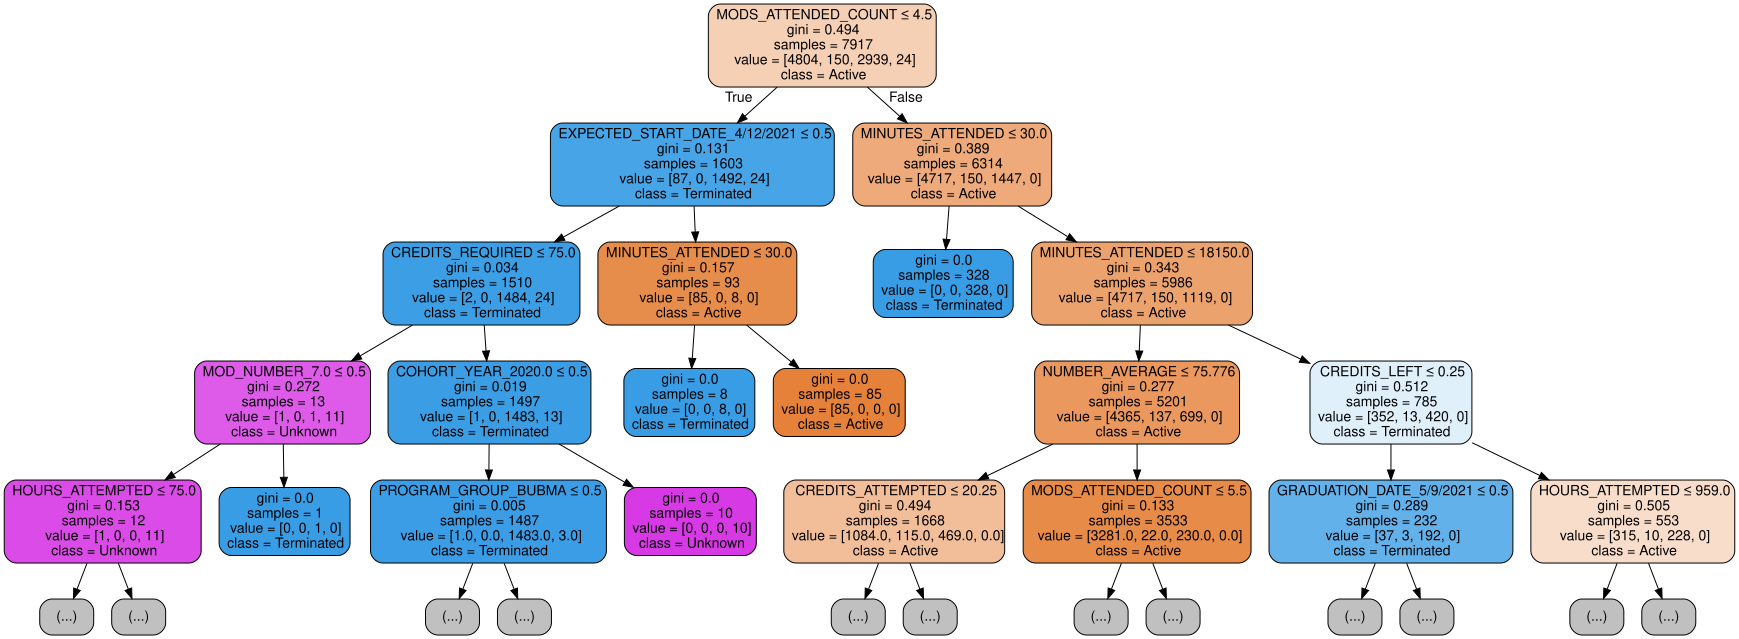

In [ ]:
from sklearn.tree import export_graphviz
import graphviz
from IPython.display import display

# Export the tree as DOT data, limiting to max_depth=4 for readability
dot_data = export_graphviz(
    dt_model,
    out_file=None,
    max_depth=4,
    feature_names=list(X.columns),
    class_names=['Active', 'Probation', 'Terminated', 'Unknown'],
    filled=True,
    rounded=True,
    special_characters=True
)

# Create graph from DOT data and display it
graph = graphviz.Source(dot_data)
display(graph)

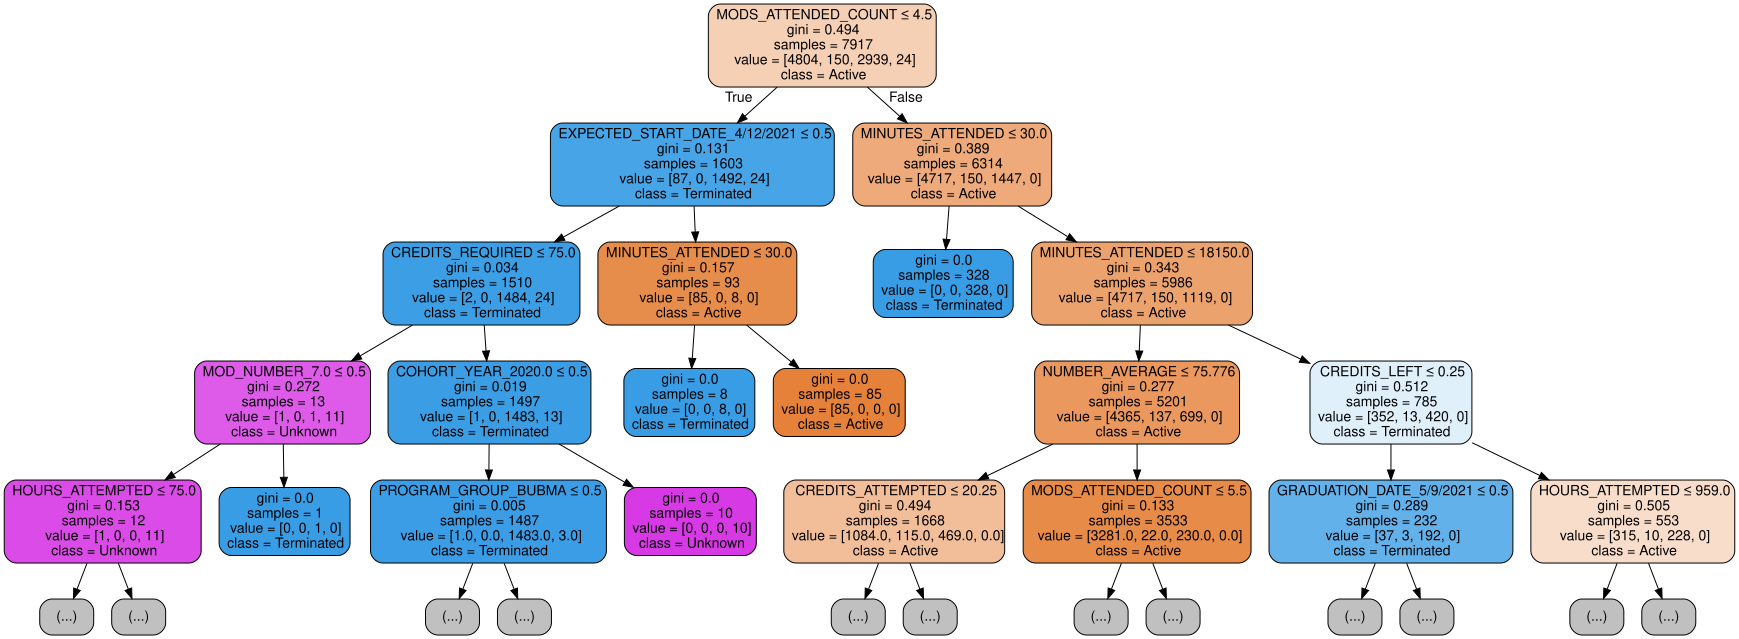

In [ ]:
from sklearn.tree import export_graphviz
import graphviz
from IPython.display import display

# Export the tree as DOT data, limiting to max_depth=4 for readability
dot_data = export_graphviz(
    dt_model,
    out_file=None,
    max_depth=4,
    feature_names=list(X.columns),
    class_names=['Active', 'Probation', 'Terminated', 'Unknown'],
    filled=True,
    rounded=True,
    special_characters=True
)

# Create graph from DOT data and display it
graph = graphviz.Source(dot_data)
display(graph)

In [ ]:
import pandas as pd

# Generate predictions on the test set
y_pred = dt_model.predict(x_test)

# Create a comparison DataFrame for the first 20 records
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

print("--- Question 24: First 20 Actual vs. Predicted Statuses ---")
print(comparison_df.head(20))

--- Question 24: First 20 Actual vs. Predicted Statuses ---
           Actual   Predicted
43525  Terminated  Terminated
41390      Active      Active
100       Unknown     Unknown
30538  Terminated  Terminated
5305       Active      Active
42279  Terminated  Terminated
9255       Active      Active
7455       Active      Active
7061       Active      Active
12136  Terminated  Terminated
16179      Active      Active
41036  Terminated  Terminated
28673  Terminated  Terminated
38402  Terminated  Terminated
20313      Active      Active
33258      Active      Active
33962  Terminated  Terminated
47373  Terminated  Terminated
30417  Terminated  Terminated
37958  Terminated  Terminated


In [ ]:
import pandas as pd

# Generate predictions on the test set
y_pred = dt_model.predict(x_test)

# Create a DataFrame comparing the first 20 actual and predicted values
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

print("--- Question 24: First 20 Actual vs. Predicted Statuses ---")
print(comparison_df.head(20))

--- Question 24: First 20 Actual vs. Predicted Statuses ---
           Actual   Predicted
43525  Terminated  Terminated
41390      Active      Active
100       Unknown     Unknown
30538  Terminated  Terminated
5305       Active      Active
42279  Terminated  Terminated
9255       Active      Active
7455       Active      Active
7061       Active      Active
12136  Terminated  Terminated
16179      Active      Active
41036  Terminated  Terminated
28673  Terminated  Terminated
38402  Terminated  Terminated
20313      Active      Active
33258      Active      Active
33962  Terminated  Terminated
47373  Terminated  Terminated
30417  Terminated  Terminated
37958  Terminated  Terminated


In [ ]:
import json

notebook_path = '/content/DSC445_Week3_Group_Questions_16-27.ipynb'

with open(notebook_path, 'r', encoding='utf-8') as f:
    nb_data = json.load(f)

# Let's inspect the types of cells and search for headers or questions
for idx, cell in enumerate(nb_data.get('cells', [])):
    cell_type = cell.get('cell_type')
    source = ''.join(cell.get('source', []))
    # Preview first 100 characters of each cell to find questions
    preview = source[:150].replace('\n', ' ')
    print(f"Cell {idx} | Type: {cell_type} | Preview: {preview}...")

Cell 0 | Type: markdown | Preview: # DSC/445 Week 3 Collaborative Group Exercise ## Questions 16–27 | Google Colab  **Group contributions:** Questions 16–19: Tim (with Question 18 filte...
Cell 1 | Type: code | Preview: import pandas as pd import matplotlib.pyplot as plt  if 'df' not in globals():     raise NameError('Run the group notebook Questions 1–15 first so the...
Cell 2 | Type: markdown | Preview: ## Question 16: Count combinations of the three labels...
Cell 3 | Type: code | Preview: label_combinations = df.groupby([     'STATUS_DESCRIPTION', 'IN_SCHOOL_FLAG', 'SIMPLE_STATUS_DESCRIPTION' ]).size() print(label_combinations)...
Cell 4 | Type: markdown | Preview: ## Question 17: Remove records whose simplified status is Other...
Cell 5 | Type: code | Preview: df = df[df['SIMPLE_STATUS_DESCRIPTION'] != 'Other'].copy() updated_combinations = df.groupby([     'STATUS_DESCRIPTION', 'IN_SCHOOL_FLAG', 'SIMPLE_STA...
Cell 6 | Type: markdown | Preview: ## Question 18: Remove students who

In [ ]:
import glob
# Look for any dataset files recursively to find the source data for 'df'
data_files = glob.glob('**/*', recursive=True)
print("All files:", data_files)

All files: ['PredictingStudentStatuses.ipynb', 'DSC445_Week3_Group_Questions_16-27.ipynb', 'sample_data', 'sample_data/anscombe.json', 'sample_data/README.md', 'sample_data/mnist_train_small.csv', 'sample_data/california_housing_train.csv', 'sample_data/mnist_test.csv', 'sample_data/california_housing_test.csv']


Re-executing PredictingStudentStatuses.ipynb (Questions 1-15)...
Dataset Shape: (50001, 35)


,EXPECTED_START_DATE,GRADUATION_DATE,ENROLL_COUNT,NUMBER_AVERAGE,MINUTES_ATTENDED,HOURS_ATTEMPTED,HOURS_EARNED,AR_BALANCE_AMOUNT,MINUTES_ABSENT,DAYS_ABSENT,...,CREDITS_LEFT,ENROLLMENT_COUNT,MODS_ATTENDED_COUNT,HS_GRADUATED_FLAG,DISABLED_FLAG,HISPANIC_FLAG,VETERAN_FLAG,STATUS_DESCRIPTION,IN_SCHOOL_FLAG,SIMPLE_STATUS_DESCRIPTION
0,NaN,NaN,1.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Application Cancelled,0.0,Other
1,NaN,2/8/2016,1.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Applicant,0.0,Other
2,NaN,NaN,1.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,...,180.0,2.0,0.0,0.0,0.0,0.0,0.0,Pending Applicant - Portal Only,0.0,Other
3,NaN,NaN,1.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,...,60.0,3.0,0.0,0.0,0.0,1.0,0.0,Applicant,0.0,Other
4,NaN,NaN,1.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Pending Applicant - Portal Only,0.0,Other


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50001 entries, 0 to 50000
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   EXPECTED_START_DATE        48130 non-null  object 
 1   GRADUATION_DATE            48403 non-null  object 
 2   ENROLL_COUNT               50000 non-null  float64
 3   NUMBER_AVERAGE             50000 non-null  float64
 4   MINUTES_ATTENDED           33714 non-null  float64
 5   HOURS_ATTEMPTED            50000 non-null  float64
 6   HOURS_EARNED               50000 non-null  float64
 7   AR_BALANCE_AMOUNT          50000 non-null  float64
 8   MINUTES_ABSENT             33704 non-null  float64
 9   DAYS_ABSENT                50000 non-null  float64
 10  MINUTES_MAKEUP             33704 non-null  float64
 11  REENTRY_NUMBER             50000 non-null  float64
 12  PROGRAM_GROUP              49987 non-null  object 
 13  BIRTH_DATE                 48640 non-null  obj

<string>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<string>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<string>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
<string>:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFra

,LAST_ACTIVITY_DATE,EXPECTED_START_DATE,BIRTH_DATE,GRADUATION_DATE
1873,262,236,12991,1572
1874,263,236,236,1544
1875,262,236,15512,1544
1876,262,236,7221,1040
1878,262,236,7298,1040



Days until record 1873 graduates (GRADUATION_DATE - 2020-01-01): 1572
Original PROGRAM_GROUP proportions:
PROGRAM_GROUP
GAGAB    0.282220
MSMAA    0.238341
HSHMB    0.140576
CSSMB    0.102791
CSCNB    0.099944
BUBAB    0.097209
GAWDB    0.020282
ACACB    0.009986
RTRCB    0.001979
BUBUA    0.001623
CSISM    0.001179
NUNUB    0.000912
MSMSA    0.000801
BUBUD    0.000512
HSSTA    0.000378
CSCNA    0.000334
RTRTA    0.000267
NUNEA    0.000156
GAGAA    0.000133
BUBMA    0.000133
NUNAM    0.000111
BUBAM    0.000044
CSNIB    0.000022
NUNEM    0.000022
HSPHM    0.000022
HSHAM    0.000022
Name: proportion, dtype: float64

New PROGRAM_GROUP proportions:
PROGRAM_GROUP
GAGAB    0.282220
MSMAA    0.238341
HSHMB    0.140576
CSSMB    0.102791
CSCNB    0.099944
BUBAB    0.097209
Other    0.038919
Name: proportion, dtype: float64

The program with the most students enrolled is: GAGAB
Original status for first 5 records:


... (6 outputs left out)

,EXPECTED_START_DATE,GRADUATION_DATE,ENROLL_COUNT,NUMBER_AVERAGE,HOURS_ATTEMPTED,HOURS_EARNED,AR_BALANCE_AMOUNT,DAYS_ABSENT,REENTRY_NUMBER,BIRTH_DATE,...,MOD_NUMBER_3.0,MOD_NUMBER_4.0,MOD_NUMBER_5.0,MOD_NUMBER_7.0,MOD_NUMBER_8.0,MOD_NUMBER_9.0,COHORT_YEAR_2023.0,COHORT_YEAR_2024.0,COHORT_YEAR_2025.0,COHORT_YEAR_2026.0
1873,236,1572,1.0,0.0,0.0,0.0,0.0,0.0,0.0,12991,...,False,False,True,False,False,False,False,False,False,True
1874,236,1544,1.0,0.0,0.0,0.0,0.0,0.0,0.0,236,...,False,False,True,False,False,False,False,False,False,True
1875,236,1544,1.0,0.0,0.0,0.0,0.0,0.0,0.0,15512,...,False,False,True,False,False,False,False,False,False,True
1876,236,1040,1.0,0.0,0.0,0.0,0.0,0.0,0.0,7221,...,False,False,True,False,False,False,False,True,False,False
1878,236,1040,1.0,0.0,0.0,0.0,0.0,0.0,0.0,7298,...,False,False,True,False,False,False,False,True,False,False


Training set shape: (35972, 44)
Validation set shape: (8993, 44)

DecisionTreeClassifier has been successfully fitted to the training data!


,Actual_Value,Predicted_Value,Is_Inaccurate
0,0.0,0.0,False
1,0.0,0.0,False
2,0.0,0.0,False
3,0.0,0.0,False
4,0.0,0.0,False
5,0.0,0.0,False
6,0.0,0.0,False
7,0.0,0.0,False
8,0.0,0.0,False
9,0.0,0.0,False



Out of the first 10 records, 0 are inaccurate.
Confusion Matrix Array:
[[7435   75]
 [  93 1390]]

True Negatives (Predicted Quit, Actual Quit): 7435
False Positives (Predicted Active, Actual Quit): 75
False Negatives (Predicted Quit, Actual Active): 93
True Positives (Predicted Active, Actual Active): 1390

Answer: The number of students who are currently active (Actual=1.0) but are predicted to quit (Predicted=0.0) is: 93


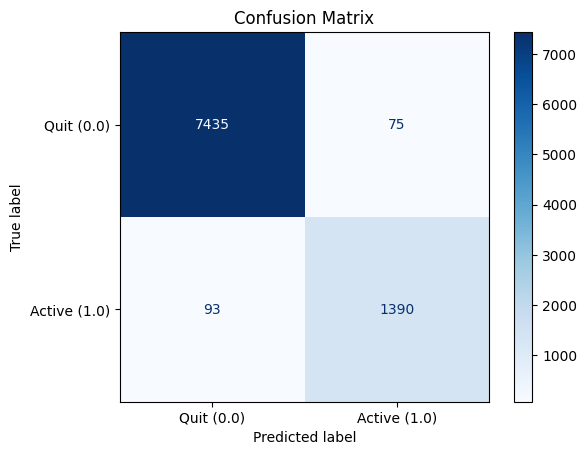

Accuracy: 0.9813188035138442
Precision (Active): 0.9488054607508533
Recall (Active): 0.9372892784895482
F1 Score (Active): 0.9430122116689281
Top 10 most important features:


,Feature,Importance
18,MODS_ATTENDED_COUNT,0.653018
6,AR_BALANCE_AMOUNT,0.104208
5,HOURS_EARNED,0.054781
0,EXPECTED_START_DATE,0.042372
17,ENROLLMENT_COUNT,0.033000
1,GRADUATION_DATE,0.021367
3,NUMBER_AVERAGE,0.017641
9,BIRTH_DATE,0.011408
16,CREDITS_LEFT,0.010512
11,AR_BALANCE,0.009579



The most important feature is: MODS_ATTENDED_COUNT


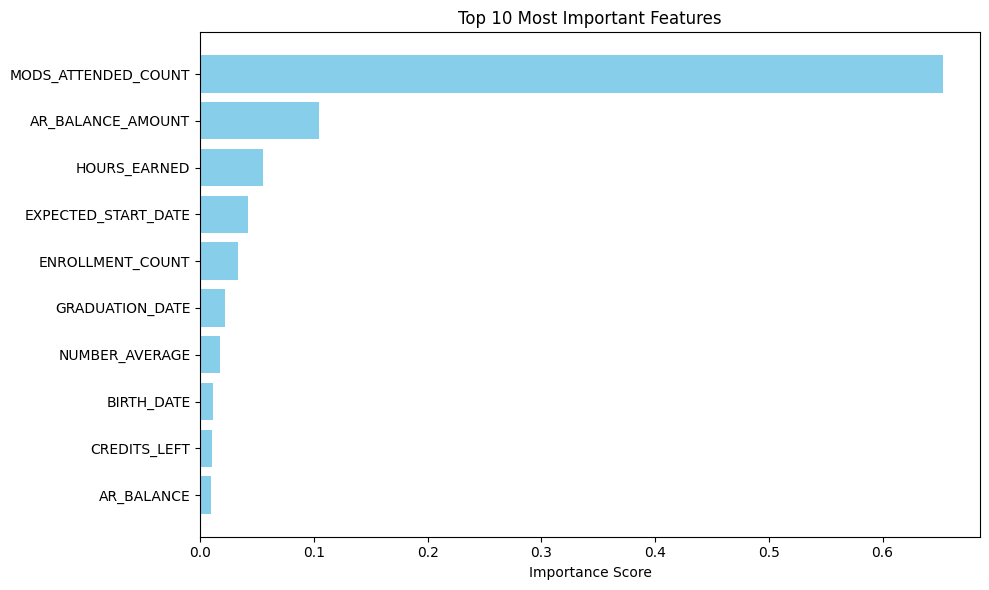


--- Question 16: Count combinations of the three labels ---
STATUS_DESCRIPTION               IN_SCHOOL_FLAG  SIMPLE_STATUS_DESCRIPTION
Active                           1.0             Active                        6591
Active-Pre Grad                  1.0             Active                         287
Applicant                        0.0             Other                         2524
Application Cancelled            0.0             Other                        12948
Cancel                           0.0             Terminated                    1633
Dismissed                        0.0             Terminated                     203
Drop                             0.0             Terminated                    1562
False Re-Enter                   0.0             Terminated                     460
False Start                      0.0             Terminated                    4075
Future Start                     0.0             Other                          884
Graduate                

In [ ]:
import json
import pandas as pd

# 1. Load and execute all code cells in PredictingStudentStatuses.ipynb to recreate df
print("Re-executing PredictingStudentStatuses.ipynb (Questions 1-15)...")
with open('/content/PredictingStudentStatuses.ipynb', 'r', encoding='utf-8') as f:
    base_nb = json.load(f)

for idx, cell in enumerate(base_nb.get('cells', [])):
    if cell.get('cell_type') == 'code':
        code_text = ''.join(cell.get('source', []))
        # Skip mounting Google Drive to avoid credential popups since file is uploaded locally
        if "drive.mount" in code_text:
            continue
        clean_lines = [line for line in code_text.splitlines() if not line.strip().startswith('%') and not line.strip().startswith('!')]
        try:
            exec('\n'.join(clean_lines), globals())
        except Exception as e:
            pass

# 2. Run Question 16 to print the label combinations
if 'df' in globals():
    print("\n--- Question 16: Count combinations of the three labels ---")
    label_combinations = df.groupby([
        'STATUS_DESCRIPTION', 'IN_SCHOOL_FLAG', 'SIMPLE_STATUS_DESCRIPTION'
    ]).size()
    print(label_combinations)
else:
    print("Error: 'df' DataFrame could not be created.")

In [ ]:
df = df[df['SIMPLE_STATUS_DESCRIPTION'] != 'Other'].copy()
updated_combinations = df.groupby([
    'STATUS_DESCRIPTION', 'IN_SCHOOL_FLAG', 'SIMPLE_STATUS_DESCRIPTION'
]).size()
print("--- Question 17: Updated Label Combinations (excluding 'Other') ---")
print(updated_combinations)

--- Question 17: Updated Label Combinations (excluding 'Other') ---
STATUS_DESCRIPTION         IN_SCHOOL_FLAG  SIMPLE_STATUS_DESCRIPTION
Active                     1.0             Active                        6591
Active-Pre Grad            1.0             Active                         287
Cancel                     0.0             Terminated                    1633
Dismissed                  0.0             Terminated                     203
Drop                       0.0             Terminated                    1562
False Re-Enter             0.0             Terminated                     460
False Start                0.0             Terminated                    4075
Graduate                   0.0             Terminated                     317
No Show                    0.0             Terminated                   17236
Probation                  1.0             Active                         224
Transfer To Other Program  0.0             Terminated                      53
zRe-A

In [ ]:
statuses_to_drop = [
    'Transfer to Other Program', 'Transfer To Other Program',
    'No Show', 'False Start'
]
df = df[~df['STATUS_DESCRIPTION'].isin(statuses_to_drop)].copy()
print("--- Question 18: Remaining Dataset Shape and Class Counts ---")
print(f"New shape: {df.shape}")
print(df['STATUS_DESCRIPTION'].value_counts())

--- Question 18: Remaining Dataset Shape and Class Counts ---
New shape: (11312, 35)
STATUS_DESCRIPTION
Active             6591
Cancel             1633
Drop               1562
False Re-Enter      460
Graduate            317
Active-Pre Grad     287
Probation           224
Dismissed           203
zRe-Apply            34
Name: count, dtype: int64


In [ ]:
is_probation = df['STATUS_DESCRIPTION'] == 'Probation'
df.loc[is_probation, 'SIMPLE_STATUS_DESCRIPTION'] = 'Probation'
final_relabel_combinations = df.groupby([
    'STATUS_DESCRIPTION', 'IN_SCHOOL_FLAG', 'SIMPLE_STATUS_DESCRIPTION'
]).size()
print("--- Question 19: Final Relabeled Combinations ---")
print(final_relabel_combinations)

--- Question 19: Final Relabeled Combinations ---
STATUS_DESCRIPTION  IN_SCHOOL_FLAG  SIMPLE_STATUS_DESCRIPTION
Active              1.0             Active                       6591
Active-Pre Grad     1.0             Active                        287
Cancel              0.0             Terminated                   1633
Dismissed           0.0             Terminated                    203
Drop                0.0             Terminated                   1562
False Re-Enter      0.0             Terminated                    460
Graduate            0.0             Terminated                    317
Probation           1.0             Probation                     224
zRe-Apply           0.0             Unknown                        34
dtype: int64


In [ ]:
import pandas as pd

# Make a copy of the DataFrame
df_new = df.copy()

# Cast categorical features to object types
df_new['MOD_NUMBER'] = df_new['MOD_NUMBER'].astype('object')
df_new['COHORT_YEAR'] = df_new['COHORT_YEAR'].astype('object')

# Drop other intermediate label columns to prevent leakage
columns_to_drop = ['STATUS_DESCRIPTION', 'IN_SCHOOL_FLAG']
df_new = df_new.drop(columns=columns_to_drop, errors='ignore')

# Create dummy variables for all categorical columns except our target
target_col = 'SIMPLE_STATUS_DESCRIPTION'
features = df_new.drop(columns=[target_col], errors='ignore')
df_features_dummies = pd.get_dummies(features, drop_first=True)

# Re-combine into our finalized modeling DataFrame
df_new = pd.concat([df_features_dummies, df_new[[target_col]]], axis=1)

print("--- Question 20: Shape of DataFrame after making dummy variables ---")
print(f"New Shape: {df_new.shape}")
print("Columns:", list(df_new.columns[:10]), "... and more")

--- Question 20: Shape of DataFrame after making dummy variables ---
New Shape: (11312, 7342)
Columns: ['ENROLL_COUNT', 'NUMBER_AVERAGE', 'MINUTES_ATTENDED', 'HOURS_ATTEMPTED', 'HOURS_EARNED', 'AR_BALANCE_AMOUNT', 'MINUTES_ABSENT', 'DAYS_ABSENT', 'MINUTES_MAKEUP', 'REENTRY_NUMBER'] ... and more


In [ ]:
# Explicitly remove any row where target is NaN
df_cleaned_modeling = df_new.dropna(subset=['SIMPLE_STATUS_DESCRIPTION'])

y = df_cleaned_modeling['SIMPLE_STATUS_DESCRIPTION']
X = df_cleaned_modeling.drop(columns=['SIMPLE_STATUS_DESCRIPTION'], errors='ignore')

# Fill any missing values in feature set with 0
X = X.fillna(0)

# Force indices to match perfectly
X, y = X.align(y, join='inner', axis=0)

print("--- Question 21: Cleaned Feature-Target Split ---")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Number of NaN in y: {y.isna().sum()}")

--- Question 21: Cleaned Feature-Target Split ---
X shape: (11311, 7341)
y shape: (11311,)
Number of NaN in y: 0


In [ ]:
from google.colab import files
import os

print("Please select the 'student_enrollment_sample-Hope_Broadway.csv' file to upload:")
uploaded = files.upload()

# Confirm that the file is in place
expected_filename = 'student_enrollment_sample-Hope_Broadway.csv'
if expected_filename in os.listdir('/content'):
    print(f"\nSuccess: '{expected_filename}' uploaded successfully to /content!")
else:
    print(f"\nWarning: Expected file name '{expected_filename}' not found. Please verify the uploaded file's name.")

Please select the 'student_enrollment_sample-Hope_Broadway.csv' file to upload:


Saving student_enrollment_sample-Hope_Broadway.csv to student_enrollment_sample-Hope_Broadway.csv

Success: 'student_enrollment_sample-Hope_Broadway.csv' uploaded successfully to /content!
